# Case Study 4 — Sentiment Analysis on Amazon Fine Food Reviews

**Goal:** classify Amazon reviews as **negative, neutral, or positive**, compare a BiLSTM baseline with a fine-tuned BERT model, and discuss transfer-learning efficiency and deployment constraints.

**Dataset:** Kaggle *Amazon Fine Food Reviews* (`Reviews.csv`).

### Label mapping
The dataset's `Score` is a 1–5 star rating. This notebook maps:
- 1–2 stars → **negative** (0)
- 3 stars → **neutral** (1)
- 4–5 stars → **positive** (2)

This is a practical proxy for sentiment, not a perfect ground-truth sentiment label: a review's wording may disagree with its star rating.

**Recommended runtime:** Google Colab with a GPU (Runtime → Change runtime type → T4 GPU). The notebook also supports CPU, but BERT fine-tuning will be much slower.

## 1. Install dependencies

Run this cell once. If Colab asks you to restart the runtime after installation, do so and continue from the next cell.

In [4]:
!pip -q install -U transformers datasets accelerate scikit-learn pandas numpy matplotlib seaborn

## 2. Imports and configuration

For a first run, keep `MAX_TRAIN_SAMPLES` and `MAX_TEST_SAMPLES` limited so the experiment finishes in a reasonable time. Set either to `None` to use the full split. BERT and the LSTM will use the **same train/test split** for a fair comparison.

In [5]:
import os, re, gc, random, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_recall_fscore_support
from sklearn.metrics import classification_report, confusion_matrix

import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from transformers import (
    AutoTokenizer, AutoModelForSequenceClassification,
    Trainer, TrainingArguments, DataCollatorWithPadding
)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)

# Change this to the path where you uploaded/saved Reviews.csv.
# In Google Colab, upload the file to the session or mount Google Drive.
CSV_PATH = "/content/Reviews.csv"

# Set to None to use all available rows. Start smaller for a quick test.
MAX_TRAIN_SAMPLES = 30000
MAX_TEST_SAMPLES = 8000

BERT_MODEL_NAME = "bert-base-uncased"
MAX_LENGTH = 192
BERT_EPOCHS = 2
BERT_BATCH_SIZE = 16
LSTM_EPOCHS = 5
LSTM_BATCH_SIZE = 128

Device: cuda


## 3. Load and inspect the Kaggle dataset

The Kaggle file normally contains columns such as `Id`, `ProductId`, `UserId`, `ProfileName`, `HelpfulnessNumerator`, `HelpfulnessDenominator`, `Score`, `Time`, `Summary`, and `Text`. Only `Score`, `Text`, and optionally `Summary` are needed here.

In [6]:
if not os.path.exists(CSV_PATH):
    raise FileNotFoundError(
        f"Could not find {CSV_PATH}. Upload Reviews.csv to this location "
        "or update CSV_PATH in the configuration cell."
    )

df = pd.read_csv(
    CSV_PATH,
    engine="python",
    on_bad_lines="warn",
    encoding="utf-8"
)

print("Shape:", df.shape)
print("Columns:", df.columns.tolist())
display(df.head())
print("Shape:", df.shape)
print("Columns:", df.columns.tolist())
display(df.head())

required = {"Score", "Text"}
missing = required - set(df.columns)
if missing:
    raise ValueError(f"Dataset is missing required columns: {missing}")

/tmp/ipykernel_1186/2234837254.py:7: ParserWarning: Skipping line 22006: unexpected end of data

  df = pd.read_csv(


Shape: (22004, 10)
Columns: ['Id', 'ProductId', 'UserId', 'ProfileName', 'HelpfulnessNumerator', 'HelpfulnessDenominator', 'Score', 'Time', 'Summary', 'Text']


,Id,ProductId,UserId,ProfileName,HelpfulnessNumerator,HelpfulnessDenominator,Score,Time,Summary,Text
0,1,B001E4KFG0,A3SGXH7AUHU8GW,delmartian,1,1,5,1303862400,Good Quality Dog Food,I have bought several of the Vitality canned d...
1,2,B00813GRG4,A1D87F6ZCVE5NK,dll pa,0,0,1,1346976000,Not as Advertised,Product arrived labeled as Jumbo Salted Peanut...
2,3,B000LQOCH0,ABXLMWJIXXAIN,"Natalia Corres ""Natalia Corres""",1,1,4,1219017600,"""Delight"" says it all",This is a confection that has been around a fe...
3,4,B000UA0QIQ,A395BORC6FGVXV,Karl,3,3,2,1307923200,Cough Medicine,If you are looking for the secret ingredient i...
4,5,B006K2ZZ7K,A1UQRSCLF8GW1T,"Michael D. Bigham ""M. Wassir""",0,0,5,1350777600,Great taffy,Great taffy at a great price. There was a wid...


Shape: (22004, 10)
Columns: ['Id', 'ProductId', 'UserId', 'ProfileName', 'HelpfulnessNumerator', 'HelpfulnessDenominator', 'Score', 'Time', 'Summary', 'Text']


,Id,ProductId,UserId,ProfileName,HelpfulnessNumerator,HelpfulnessDenominator,Score,Time,Summary,Text
0,1,B001E4KFG0,A3SGXH7AUHU8GW,delmartian,1,1,5,1303862400,Good Quality Dog Food,I have bought several of the Vitality canned d...
1,2,B00813GRG4,A1D87F6ZCVE5NK,dll pa,0,0,1,1346976000,Not as Advertised,Product arrived labeled as Jumbo Salted Peanut...
2,3,B000LQOCH0,ABXLMWJIXXAIN,"Natalia Corres ""Natalia Corres""",1,1,4,1219017600,"""Delight"" says it all",This is a confection that has been around a fe...
3,4,B000UA0QIQ,A395BORC6FGVXV,Karl,3,3,2,1307923200,Cough Medicine,If you are looking for the secret ingredient i...
4,5,B006K2ZZ7K,A1UQRSCLF8GW1T,"Michael D. Bigham ""M. Wassir""",0,0,5,1350777600,Great taffy,Great taffy at a great price. There was a wid...


## 4. Clean the data and create three sentiment classes

We combine `Summary` and `Text` when a summary is available. Empty reviews are removed, exact duplicate review texts are dropped, and star ratings are mapped to the three target classes.

In [7]:
df = df.dropna(subset=["Score", "Text"]).copy()
df["Score"] = pd.to_numeric(df["Score"], errors="coerce")
df = df.dropna(subset=["Score"])
df = df[df["Score"].between(1, 5)]

if "Summary" in df.columns:
    summary = df["Summary"].fillna("").astype(str).str.strip()
    body = df["Text"].fillna("").astype(str).str.strip()
    df["review"] = (summary + ". " + body).str.strip(". ")
else:
    df["review"] = df["Text"].astype(str)

df["review"] = df["review"].str.replace(r"\s+", " ", regex=True).str.strip()
df = df[df["review"].str.len() > 0]
df = df.drop_duplicates(subset=["review"]).copy()

def score_to_label(score):
    if score <= 2:
        return 0  # negative
    elif score == 3:
        return 1  # neutral
    return 2      # positive

df["label"] = df["Score"].apply(score_to_label).astype(int)

LABEL_NAMES = ["negative", "neutral", "positive"]
print("Cleaned shape:", df.shape)
display(df[["Score", "review", "label"]].head())
print(df["label"].value_counts().sort_index().rename(index=dict(enumerate(LABEL_NAMES))))

Cleaned shape: (21277, 12)


,Score,review,label
0,5,Good Quality Dog Food. I have bought several o...,2
1,1,Not as Advertised. Product arrived labeled as ...,0
2,4,"""Delight"" says it all. This is a confection th...",2
3,2,Cough Medicine. If you are looking for the sec...,0
4,5,Great taffy. Great taffy at a great price. The...,2


label
negative     3061
neutral      1742
positive    16474
Name: count, dtype: int64


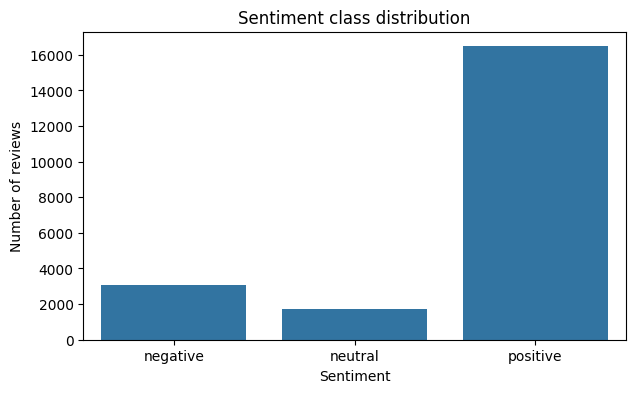

In [8]:
plt.figure(figsize=(7, 4))
sns.countplot(data=df, x="label", order=[0, 1, 2])
plt.xticks([0, 1, 2], LABEL_NAMES)
plt.title("Sentiment class distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of reviews")
plt.show()

## 5. Train/test split

We use a stratified split to preserve class proportions. A small validation split is then taken from the training data for model selection.

In [9]:
data = df[["review", "label"]].copy()

# Optional stratified sampling for a manageable experiment.
if MAX_TRAIN_SAMPLES is not None or MAX_TEST_SAMPLES is not None:
    # First split, then cap each partition while preserving class proportions.
    train_df, test_df = train_test_split(
        data, test_size=0.20, random_state=SEED, stratify=data["label"]
    )
    if MAX_TRAIN_SAMPLES is not None and len(train_df) > MAX_TRAIN_SAMPLES:
        train_df, _ = train_test_split(
            train_df, train_size=MAX_TRAIN_SAMPLES, random_state=SEED,
            stratify=train_df["label"]
        )
    if MAX_TEST_SAMPLES is not None and len(test_df) > MAX_TEST_SAMPLES:
        test_df, _ = train_test_split(
            test_df, train_size=MAX_TEST_SAMPLES, random_state=SEED,
            stratify=test_df["label"]
        )
else:
    train_df, test_df = train_test_split(
        data, test_size=0.20, random_state=SEED, stratify=data["label"]
    )

train_df, val_df = train_test_split(
    train_df, test_size=0.10, random_state=SEED, stratify=train_df["label"]
)

print(f"Train: {len(train_df):,} | Validation: {len(val_df):,} | Test: {len(test_df):,}")

Train: 15,318 | Validation: 1,703 | Test: 4,256


# Part A — LSTM baseline

The baseline is a bidirectional LSTM with a trainable embedding layer. It is trained from scratch on this dataset (no pretrained language model). Tokenization uses a simple Keras tokenizer-style vocabulary built from the training reviews only.

In [10]:
from collections import Counter

VOCAB_SIZE = 30000
LSTM_MAX_LENGTH = 192

def basic_tokenize(text):
    return re.findall(r"[a-z0-9']+", str(text).lower())

counter = Counter()
for review in train_df["review"]:
    counter.update(basic_tokenize(review))

vocab = {"<PAD>": 0, "<UNK>": 1}
for word, _ in counter.most_common(VOCAB_SIZE - 2):
    vocab[word] = len(vocab)

def encode_review(text, max_length=LSTM_MAX_LENGTH):
    ids = [vocab.get(w, 1) for w in basic_tokenize(text)][:max_length]
    ids += [0] * (max_length - len(ids))
    return ids

class ReviewDataset(Dataset):
    def __init__(self, frame):
        self.texts = frame["review"].tolist()
        self.labels = frame["label"].astype(int).tolist()
    def __len__(self):
        return len(self.labels)
    def __getitem__(self, idx):
        return (
            torch.tensor(encode_review(self.texts[idx]), dtype=torch.long),
            torch.tensor(self.labels[idx], dtype=torch.long)
        )

lstm_train_ds = ReviewDataset(train_df)
lstm_val_ds = ReviewDataset(val_df)
lstm_test_ds = ReviewDataset(test_df)

lstm_train_loader = DataLoader(lstm_train_ds, batch_size=LSTM_BATCH_SIZE, shuffle=True)
lstm_val_loader = DataLoader(lstm_val_ds, batch_size=LSTM_BATCH_SIZE)
lstm_test_loader = DataLoader(lstm_test_ds, batch_size=LSTM_BATCH_SIZE)

print("Vocabulary size:", len(vocab))

Vocabulary size: 26328


In [11]:
class BiLSTMClassifier(nn.Module):
    def __init__(self, vocab_size, embedding_dim=128, hidden_dim=128, num_classes=3, pad_idx=0):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=pad_idx)
        self.lstm = nn.LSTM(
            embedding_dim, hidden_dim, batch_first=True,
            bidirectional=True, num_layers=1
        )
        self.dropout = nn.Dropout(0.35)
        self.fc = nn.Linear(hidden_dim * 2, num_classes)

    def forward(self, input_ids):
        embedded = self.embedding(input_ids)
        _, (hidden, _) = self.lstm(embedded)
        # Last layer's forward and backward hidden states
        final = torch.cat((hidden[-2], hidden[-1]), dim=1)
        return self.fc(self.dropout(final))

lstm_model = BiLSTMClassifier(len(vocab)).to(DEVICE)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(lstm_model.parameters(), lr=1e-3)

def evaluate_torch_model(model, loader):
    model.eval()
    all_preds, all_labels = [], []
    total_loss, total_count = 0.0, 0
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            logits = model(x)
            loss = criterion(logits, y)
            total_loss += loss.item() * y.size(0)
            total_count += y.size(0)
            all_preds.extend(logits.argmax(1).cpu().numpy())
            all_labels.extend(y.cpu().numpy())
    return total_loss / total_count, np.array(all_labels), np.array(all_preds)

best_val_loss = float("inf")
best_lstm_state = None
lstm_start = time.time()

for epoch in range(LSTM_EPOCHS):
    lstm_model.train()
    running_loss, seen = 0.0, 0
    for x, y in lstm_train_loader:
        x, y = x.to(DEVICE), y.to(DEVICE)
        optimizer.zero_grad()
        logits = lstm_model(x)
        loss = criterion(logits, y)
        loss.backward()
        nn.utils.clip_grad_norm_(lstm_model.parameters(), 1.0)
        optimizer.step()
        running_loss += loss.item() * y.size(0)
        seen += y.size(0)

    val_loss, val_y, val_pred = evaluate_torch_model(lstm_model, lstm_val_loader)
    val_acc = accuracy_score(val_y, val_pred)
    print(f"Epoch {epoch+1}/{LSTM_EPOCHS} | train loss={running_loss/seen:.4f} "
          f"| val loss={val_loss:.4f} | val accuracy={val_acc:.4f}")

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_lstm_state = {k: v.detach().cpu().clone() for k, v in lstm_model.state_dict().items()}

lstm_train_seconds = time.time() - lstm_start
lstm_model.load_state_dict(best_lstm_state)
print(f"LSTM training time: {lstm_train_seconds/60:.1f} minutes")

Epoch 1/5 | train loss=0.5891 | val loss=0.4979 | val accuracy=0.7980
Epoch 2/5 | train loss=0.4313 | val loss=0.4495 | val accuracy=0.8356
Epoch 3/5 | train loss=0.3584 | val loss=0.4361 | val accuracy=0.8256
Epoch 4/5 | train loss=0.2974 | val loss=0.4310 | val accuracy=0.8403
Epoch 5/5 | train loss=0.2459 | val loss=0.4609 | val accuracy=0.8373
LSTM training time: 0.6 minutes


In [12]:
lstm_test_loss, y_test_lstm, y_pred_lstm = evaluate_torch_model(lstm_model, lstm_test_loader)
print(classification_report(y_test_lstm, y_pred_lstm, target_names=LABEL_NAMES, digits=4))

              precision    recall  f1-score   support

    negative     0.6468    0.6373    0.6420       612
     neutral     0.4397    0.1777    0.2531       349
    positive     0.8927    0.9514    0.9211      3295

    accuracy                         0.8428      4256
   macro avg     0.6597    0.5888    0.6054      4256
weighted avg     0.8202    0.8428    0.8262      4256



# Part B — Fine-tune BERT with Hugging Face

BERT starts with language representations learned from large-scale text pretraining. Fine-tuning updates the pretrained model's weights for this three-class review task. This is **transfer learning**.

In [13]:
tokenizer = AutoTokenizer.from_pretrained(BERT_MODEL_NAME)

class BertReviewDataset(Dataset):
    def __init__(self, frame, tokenizer, max_length=MAX_LENGTH):
        self.texts = frame["review"].tolist()
        self.labels = frame["label"].astype(int).tolist()
        self.tokenizer = tokenizer
        self.max_length = max_length

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        item = self.tokenizer(
            self.texts[idx],
            truncation=True,
            max_length=self.max_length,
            padding="max_length",
            return_tensors="pt"
        )
        return {
            "input_ids": item["input_ids"].squeeze(0),
            "attention_mask": item["attention_mask"].squeeze(0),
            "labels": torch.tensor(self.labels[idx], dtype=torch.long)
        }

bert_train_ds = BertReviewDataset(train_df, tokenizer)
bert_val_ds = BertReviewDataset(val_df, tokenizer)
bert_test_ds = BertReviewDataset(test_df, tokenizer)

bert_model = AutoModelForSequenceClassification.from_pretrained(
    BERT_MODEL_NAME, num_labels=3,
    id2label={0: "negative", 1: "neutral", 2: "positive"},
    label2id={"negative": 0, "neutral": 1, "positive": 2}
)

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [14]:
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)
    precision, recall, f1, _ = precision_recall_fscore_support(
        labels, preds, average="macro", zero_division=0
    )
    return {
        "accuracy": accuracy_score(labels, preds),
        "macro_f1": f1,
        "macro_precision": precision,
        "macro_recall": recall
    }

# Hugging Face has used both evaluation_strategy and eval_strategy across versions.
# This cell checks the installed version and uses the supported argument name.
import inspect
training_args_params = inspect.signature(TrainingArguments.__init__).parameters
eval_key = "eval_strategy" if "eval_strategy" in training_args_params else "evaluation_strategy"

training_kwargs = dict(
    output_dir="./bert_amazon_sentiment",
    learning_rate=2e-5,
    per_device_train_batch_size=BERT_BATCH_SIZE,
    per_device_eval_batch_size=BERT_BATCH_SIZE,
    num_train_epochs=BERT_EPOCHS,
    weight_decay=0.01,
    logging_steps=100,
    save_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="macro_f1",
    greater_is_better=True,
    report_to="none",
    fp16=torch.cuda.is_available(),
    seed=SEED
)
training_kwargs[eval_key] = "epoch"
training_args = TrainingArguments(**training_kwargs)

trainer = Trainer(
    model=bert_model,
    args=training_args,
    train_dataset=bert_train_ds,
    eval_dataset=bert_val_ds,
    compute_metrics=compute_metrics
)

bert_start = time.time()
trainer.train()
bert_train_seconds = time.time() - bert_start
print(f"BERT fine-tuning time: {bert_train_seconds/60:.1f} minutes")

Epoch,Training Loss,Validation Loss,Accuracy,Macro F1,Macro Precision,Macro Recall
1,0.280323,0.302803,0.892543,0.665550,0.775726,0.646387
2,0.190790,0.281094,0.906048,0.751513,0.773539,0.738295


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[transformers] There were missing keys in the checkpoint model loaded: ['bert.embeddings.LayerNorm.weight', 'bert.embeddings.LayerNorm.bias', 'bert.encoder.layer.0.attention.output.LayerNorm.weight', 'bert.encoder.layer.0.attention.output.LayerNorm.bias', 'bert.encoder.layer.0.output.LayerNorm.weight', 'bert.encoder.layer.0.output.LayerNorm.bias', 'bert.encoder.layer.1.attention.output.LayerNorm.weight', 'bert.encoder.layer.1.attention.output.LayerNorm.bias', 'bert.encoder.layer.1.output.LayerNorm.weight', 'bert.encoder.layer.1.output.LayerNorm.bias', 'bert.encoder.layer.2.attention.output.LayerNorm.weight', 'bert.encoder.layer.2.attention.output.LayerNorm.bias', 'bert.encoder.layer.2.output.LayerNorm.weight', 'bert.encoder.layer.2.output.LayerNorm.bias', 'bert.encoder.layer.3.attention.output.LayerNorm.weight', 'bert.encoder.layer.3.attention.output.LayerNorm.bias', 'bert.encoder.layer.3.output.LayerNorm.weight', 'bert.encoder.layer.3.output.LayerNorm.bias', 'bert.encoder.layer.4.atte

BERT fine-tuning time: 5.6 minutes


In [15]:
bert_test_output = trainer.predict(bert_test_ds)
y_test_bert = bert_test_output.label_ids
y_pred_bert = np.argmax(bert_test_output.predictions, axis=-1)

print(classification_report(y_test_bert, y_pred_bert, target_names=LABEL_NAMES, digits=4))

              precision    recall  f1-score   support

    negative     0.8053    0.8382    0.8215       612
     neutral     0.5115    0.3811    0.4368       349
    positive     0.9500    0.9684    0.9591      3295

    accuracy                         0.9016      4256
   macro avg     0.7556    0.7293    0.7391      4256
weighted avg     0.8932    0.9016    0.8965      4256



## 6. Compare the models

Accuracy alone can hide poor performance on the smaller neutral class. Macro-F1 gives each class equal weight, so it is especially useful when class counts are imbalanced.

In [16]:
def metric_row(name, y_true, y_pred, train_seconds):
    p, r, f1, _ = precision_recall_fscore_support(
        y_true, y_pred, average="macro", zero_division=0
    )
    return {
        "Model": name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Macro Precision": p,
        "Macro Recall": r,
        "Macro F1": f1,
        "Training time (minutes)": train_seconds / 60
    }

results = pd.DataFrame([
    metric_row("BiLSTM baseline", y_test_lstm, y_pred_lstm, lstm_train_seconds),
    metric_row("Fine-tuned BERT", y_test_bert, y_pred_bert, bert_train_seconds)
])
display(results.round(4))

,Model,Accuracy,Macro Precision,Macro Recall,Macro F1,Training time (minutes)
0,BiLSTM baseline,0.8428,0.6597,0.5888,0.6054,0.5858
1,Fine-tuned BERT,0.9016,0.7556,0.7293,0.7391,5.5644


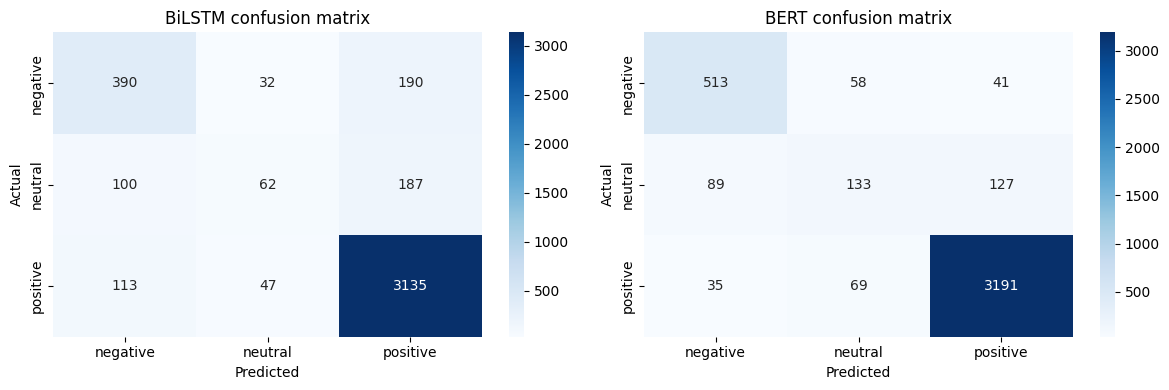

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, title, y_true, y_pred in [
    (axes[0], "BiLSTM confusion matrix", y_test_lstm, y_pred_lstm),
    (axes[1], "BERT confusion matrix", y_test_bert, y_pred_bert)
]:
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1, 2])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=LABEL_NAMES, yticklabels=LABEL_NAMES, ax=ax)
    ax.set_title(title)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
plt.tight_layout()
plt.show()

## 7. Try the models on your own reviews

The function below returns both model predictions. Remember that the output is a model estimate, not a guarantee that the review's star rating or true sentiment is known.

In [18]:
def predict_sentiment(review_text):
    # LSTM prediction
    ids = torch.tensor([encode_review(review_text)], dtype=torch.long).to(DEVICE)
    lstm_model.eval()
    with torch.no_grad():
        lstm_probs = torch.softmax(lstm_model(ids), dim=1)[0].cpu().numpy()

    # BERT prediction
    bert_inputs = tokenizer(
        review_text, return_tensors="pt", truncation=True,
        padding=True, max_length=MAX_LENGTH
    ).to(bert_model.device)
    bert_model.eval()
    with torch.no_grad():
        bert_probs = torch.softmax(bert_model(**bert_inputs).logits, dim=1)[0].cpu().numpy()

    return pd.DataFrame({
        "Sentiment": LABEL_NAMES,
        "BiLSTM probability": lstm_probs,
        "BERT probability": bert_probs
    }).sort_values("BERT probability", ascending=False)

sample_review = "The product arrived quickly and tastes great. I would buy it again."
display(predict_sentiment(sample_review))

,Sentiment,BiLSTM probability,BERT probability
2,positive,0.961853,0.998160
1,neutral,0.020116,0.001353
0,negative,0.018030,0.000487


## 8. Save the trained models

These files can be downloaded from Colab's file browser or copied to Google Drive. Keep the tokenizer with the BERT model.

In [19]:
os.makedirs("saved_models", exist_ok=True)

torch.save({
    "model_state_dict": lstm_model.state_dict(),
    "vocab": vocab,
    "max_length": LSTM_MAX_LENGTH,
    "label_names": LABEL_NAMES
}, "saved_models/bilstm_sentiment.pt")

trainer.save_model("saved_models/bert_sentiment")
tokenizer.save_pretrained("saved_models/bert_sentiment")

print("Saved models under ./saved_models/")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Saved models under ./saved_models/


In [20]:
print(classification_report(
    y_test_bert,
    y_pred_bert,
    target_names=LABEL_NAMES,
    digits=4
))

              precision    recall  f1-score   support

    negative     0.8053    0.8382    0.8215       612
     neutral     0.5115    0.3811    0.4368       349
    positive     0.9500    0.9684    0.9591      3295

    accuracy                         0.9016      4256
   macro avg     0.7556    0.7293    0.7391      4256
weighted avg     0.8932    0.9016    0.8965      4256



# 9. Case-study discussion and conclusions

Complete this section **after running the notebook**. Insert your measured results from the comparison table rather than inventing performance numbers.

### A. Which model performed better?
Compare test accuracy and macro-F1. Explain which sentiment class was hardest to predict using the classification reports and confusion matrices. In this dataset, neutral reviews may be harder because the three-star class is usually much smaller and its language can overlap with both positive and negative reviews.

### B. Transfer-learning efficiency
- **BERT advantage:** it begins with contextual language representations learned during large-scale pretraining. Fine-tuning typically needs less task-specific labelled data and can capture context, negation, and word relationships better than a model trained from scratch.
- **LSTM baseline:** it is a useful comparison and may be smaller or cheaper to serve, but its embedding and sequence representations are learned only from this task's training data.
- **Important distinction:** BERT fine-tuning is not free. It still requires GPU memory and compute, and the full BERT model is relatively large. Compare your actual training times and scores.

### C. Real-world deployment constraints
1. **Latency and throughput:** BERT inference is heavier than a compact LSTM. Measure requests/second and p50/p95 latency on the intended hardware.
2. **Cost and hardware:** GPU hosting can improve throughput but increases infrastructure cost. CPU inference, quantization, distillation, or a smaller model may be preferable for high-volume or low-cost deployments.
3. **Input length:** this notebook truncates reviews at `MAX_LENGTH`. Important sentiment near the end of long reviews may be lost. Consider chunking long reviews and aggregating predictions.
4. **Class imbalance and calibration:** monitor per-class precision/recall, especially neutral sentiment. Consider class weights or resampling if minority-class performance is poor. Calibrate probabilities before using confidence thresholds.
5. **Data quality and label noise:** star ratings are only a proxy for sentiment. A one-star review can contain positive comments and vice versa. Human-labelled sentiment examples would provide a stronger evaluation.
6. **Data leakage and generalization:** duplicate removal helps, but future work should split by time or product/user to test generalization to new products and later reviews.
7. **Privacy and monitoring:** remove personal information where possible, define retention rules, monitor drift, and periodically evaluate on newly labelled reviews.

### D. Final conclusion template
> On the held-out test set, the BiLSTM achieved **[accuracy] accuracy** and **[macro-F1] macro-F1**, while fine-tuned BERT achieved **[accuracy] accuracy** and **[macro-F1] macro-F1**. The better model was **[model]** based on **[metric/reason]**. BERT benefited from pretrained contextual representations, while the BiLSTM provided a simpler baseline. For deployment, the final choice should balance predictive quality with latency, throughput, model size, hardware cost, and ongoing monitoring.

### Limitations of this experiment
- Results depend on the selected sample size, random seed, hyperparameters, and compute hardware.
- The three-class labels are derived from star ratings rather than manually annotated sentiment.
- A random split may overestimate performance on future reviews or unseen products.
- A single run is not enough to establish that one model is consistently superior; repeat with multiple seeds for a stronger study.

## 10. Optional improvements for a stronger submission

- Run with the full dataset and compare the change in performance and training time.
- Try `distilbert-base-uncased` to study the speed/accuracy trade-off.
- Tune the learning rate (for example, `2e-5`, `3e-5`, `5e-5`) and maximum sequence length.
- Add a product-wise or time-based test split to test real-world generalization.
- Record GPU type, runtime, dataset size, and model parameter count in your report.